В цьому ноутбуці відбуваєтся перевірка одного активу на рандомних відрізках часу. Метою є перевірка чи отримані загальні результати релевантні для різних режимів ринку

In [1]:
import os
os.chdir("..")

In [2]:
import pandas as pd
import numpy as np

import random
import yaml

from app import BacktestDCA
from ploter import ploter

/Users/aleksejkitajskij/Desktop/DCA/venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
STOCK = 'ETH'
SEQUENCE_LENGTH = 365 * 4
N_PERIODS = 10

# stocks

In [4]:
df_stocks = pd.read_csv("data/test_crypto.csv", index_col=0, parse_dates=True)
df_stocks

,BTC,ETH,XRP,BNB,ADA,SOL,DOGE,DOT,LTC,LINK,...,XVG,BCN,NXT,PPC,NMC,DGB,SC,QTUM,ICX,LSK
Date,,,,,,,,,,,,,,,,,,,,,
2014-09-17,457.334015,NaN,NaN,NaN,NaN,NaN,NaN,NaN,5.058550,NaN,...,NaN,NaN,NaN,1.540270,1.264560,NaN,NaN,NaN,NaN,NaN
2014-09-18,424.440002,NaN,NaN,NaN,NaN,NaN,NaN,NaN,4.685230,NaN,...,NaN,NaN,NaN,1.685280,1.229760,NaN,NaN,NaN,NaN,NaN
2014-09-19,394.795990,NaN,NaN,NaN,NaN,NaN,NaN,NaN,4.327770,NaN,...,NaN,NaN,NaN,1.216330,1.104190,NaN,NaN,NaN,NaN,NaN
2014-09-20,408.903992,NaN,NaN,NaN,NaN,NaN,NaN,NaN,4.286440,NaN,...,NaN,NaN,NaN,1.641050,1.194410,NaN,NaN,NaN,NaN,NaN
2014-09-21,398.821014,NaN,NaN,NaN,NaN,NaN,NaN,NaN,4.245920,NaN,...,NaN,NaN,NaN,1.488790,1.110980,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2026-10-20,82941.000000,2446.730713,1.334452,740.823608,0.223782,106.422340,0.081809,1.149771,61.531612,12.320927,...,0.002583,0.000059,NaN,0.446449,1.317299,0.003360,0.000820,0.877745,0.009176,0.197685
2026-10-21,84011.968750,2470.766113,1.363619,745.868347,0.224979,106.793655,0.081867,1.141323,61.454342,12.484719,...,0.002605,0.000037,NaN,0.343409,1.176803,0.003399,0.000850,0.889200,0.008703,0.196787
2026-10-22,81311.890625,2386.189209,1.307656,730.476624,0.212025,103.542320,0.078676,1.111869,58.756485,11.943166,...,0.002455,0.000029,NaN,0.342047,1.535211,0.003527,0.000893,0.852186,0.009433,0.183983


In [5]:
asset_prices = df_stocks[STOCK].dropna()

periods = []
for i in range(N_PERIODS):
    start = random.randint(0, len(asset_prices) - SEQUENCE_LENGTH)
    period_prices = asset_prices.iloc[start:start + SEQUENCE_LENGTH]
    periods.append({
        "period_id": i + 1,
        "start": period_prices.index.min(),
        "end": period_prices.index.max(),
        "prices": period_prices,
    })

In [6]:
pd.DataFrame(
    [{"period": p["period_id"], "start": p["start"], "end": p["end"], "days": len(p["prices"])} for p in periods]
 )

,period,start,end,days
0,1,2018-12-12,2022-12-10,1460
1,2,2021-10-25,2025-10-23,1460
2,3,2019-05-11,2023-05-09,1460
3,4,2020-10-08,2024-10-06,1460
4,5,2020-10-23,2024-10-21,1460
5,6,2021-11-10,2025-11-08,1460
6,7,2020-01-03,2024-01-01,1460
7,8,2022-06-24,2026-06-22,1460
8,9,2019-08-26,2023-08-24,1460
9,10,2018-12-01,2022-11-29,1460


In [7]:
strategy = {
    "buy_amount": 10,
}

19:04:45 - cmdstanpy - INFO - Chain [1] start processing
19:04:46 - cmdstanpy - INFO - Chain [1] done processing


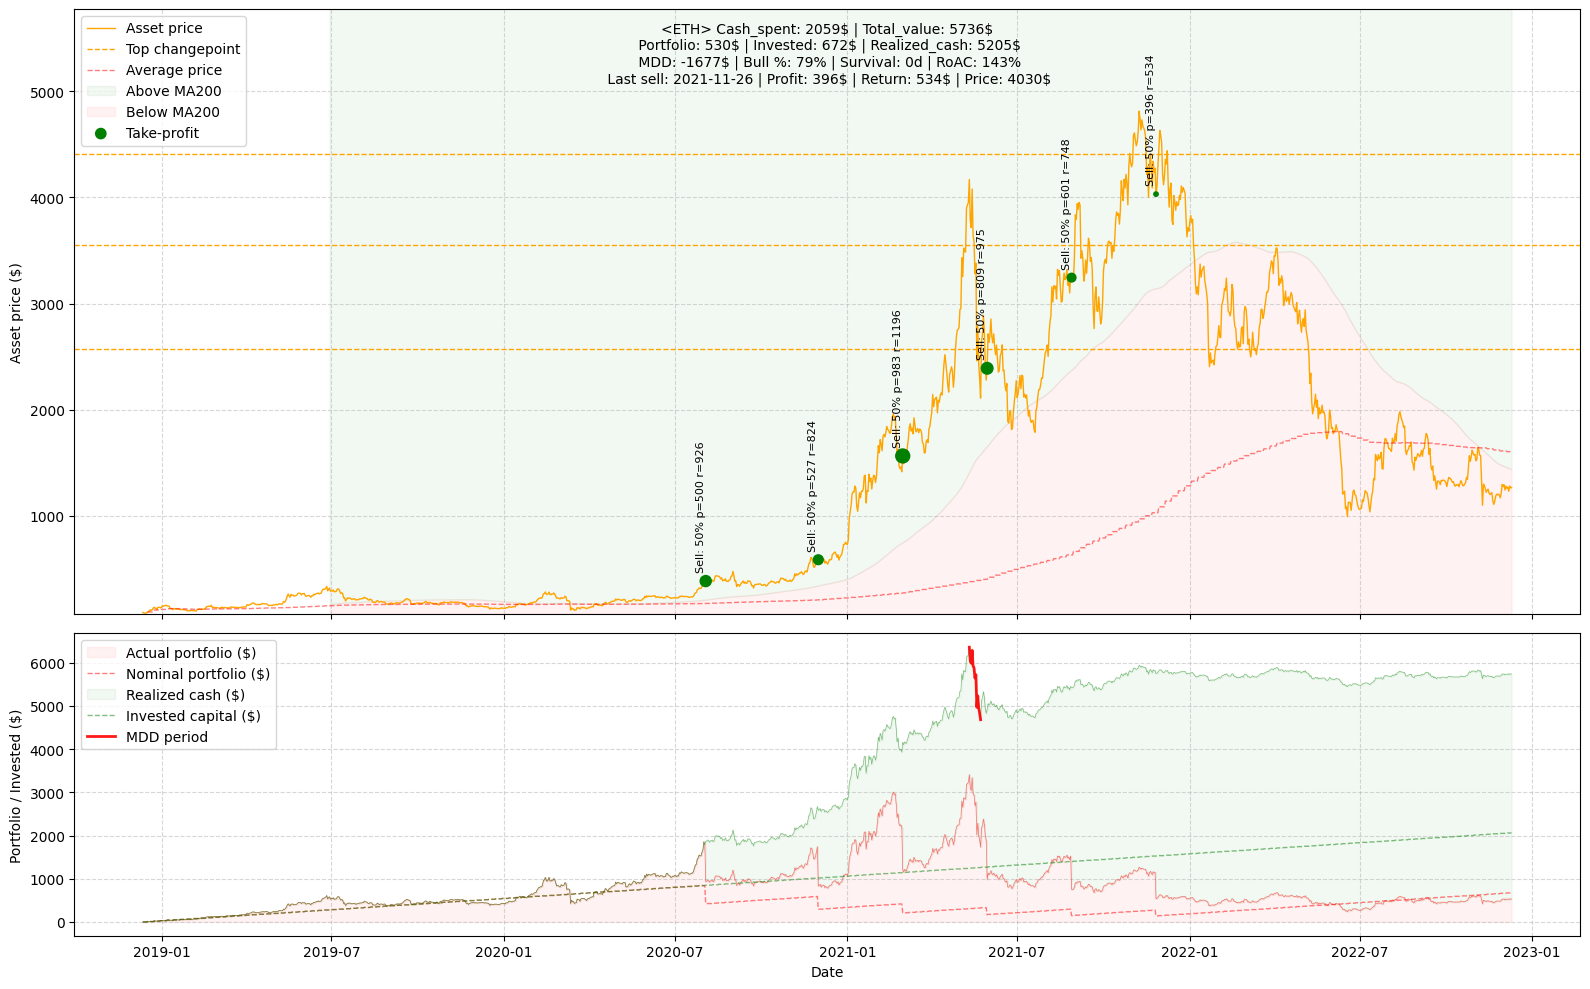

19:04:46 - cmdstanpy - INFO - Chain [1] start processing
19:04:46 - cmdstanpy - INFO - Chain [1] done processing


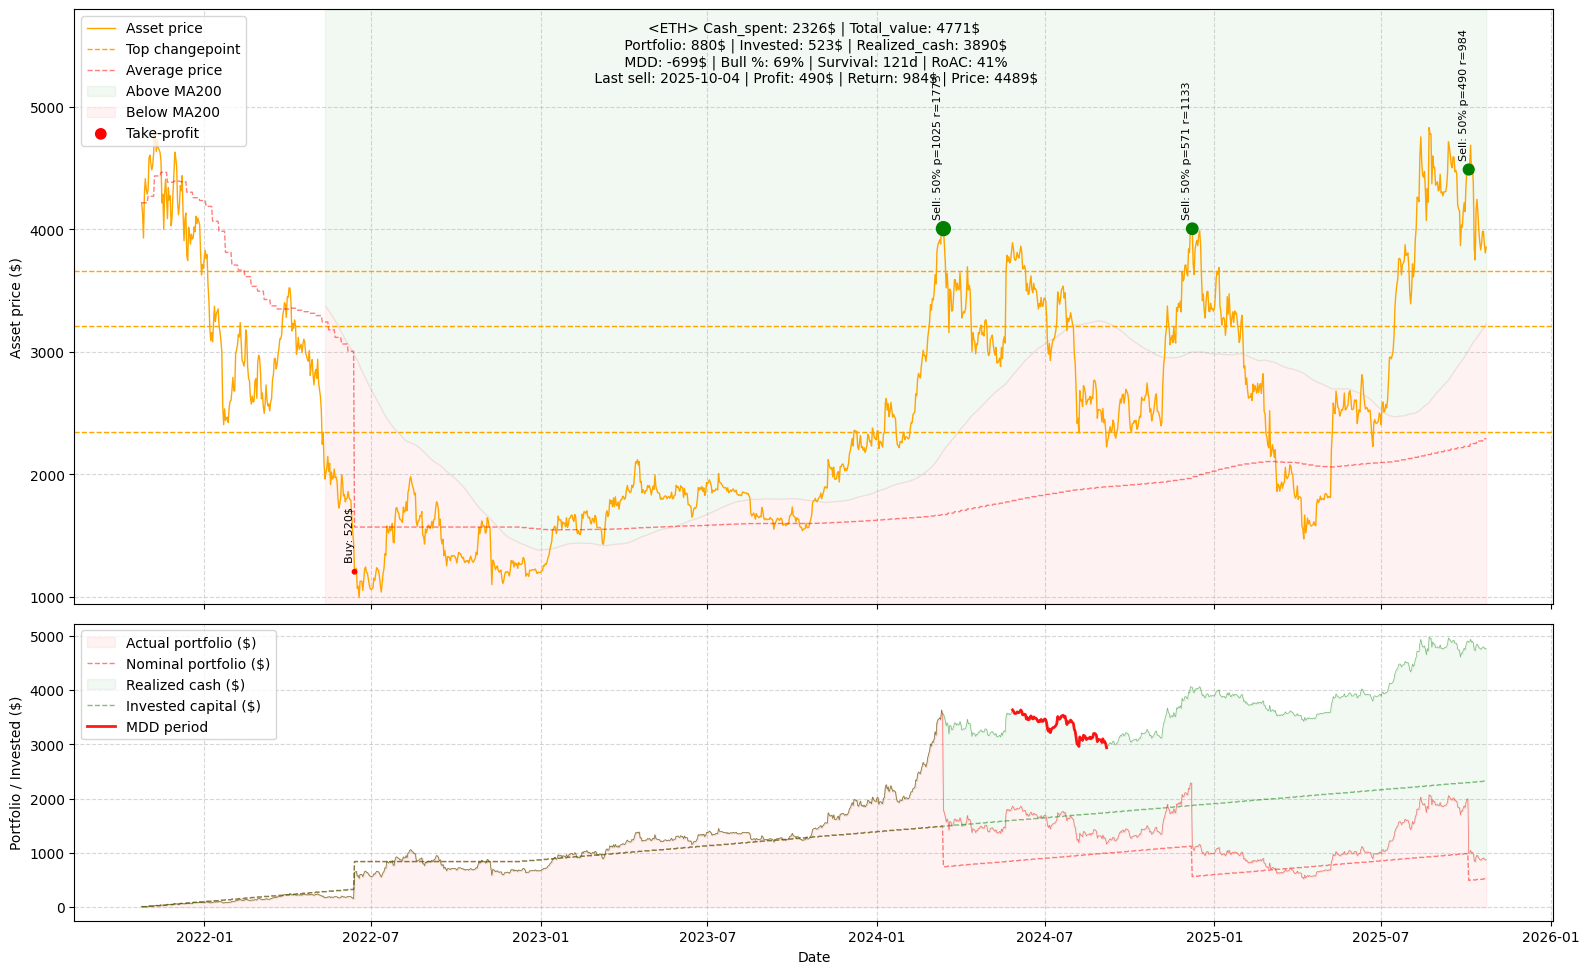

19:04:47 - cmdstanpy - INFO - Chain [1] start processing
19:04:47 - cmdstanpy - INFO - Chain [1] done processing


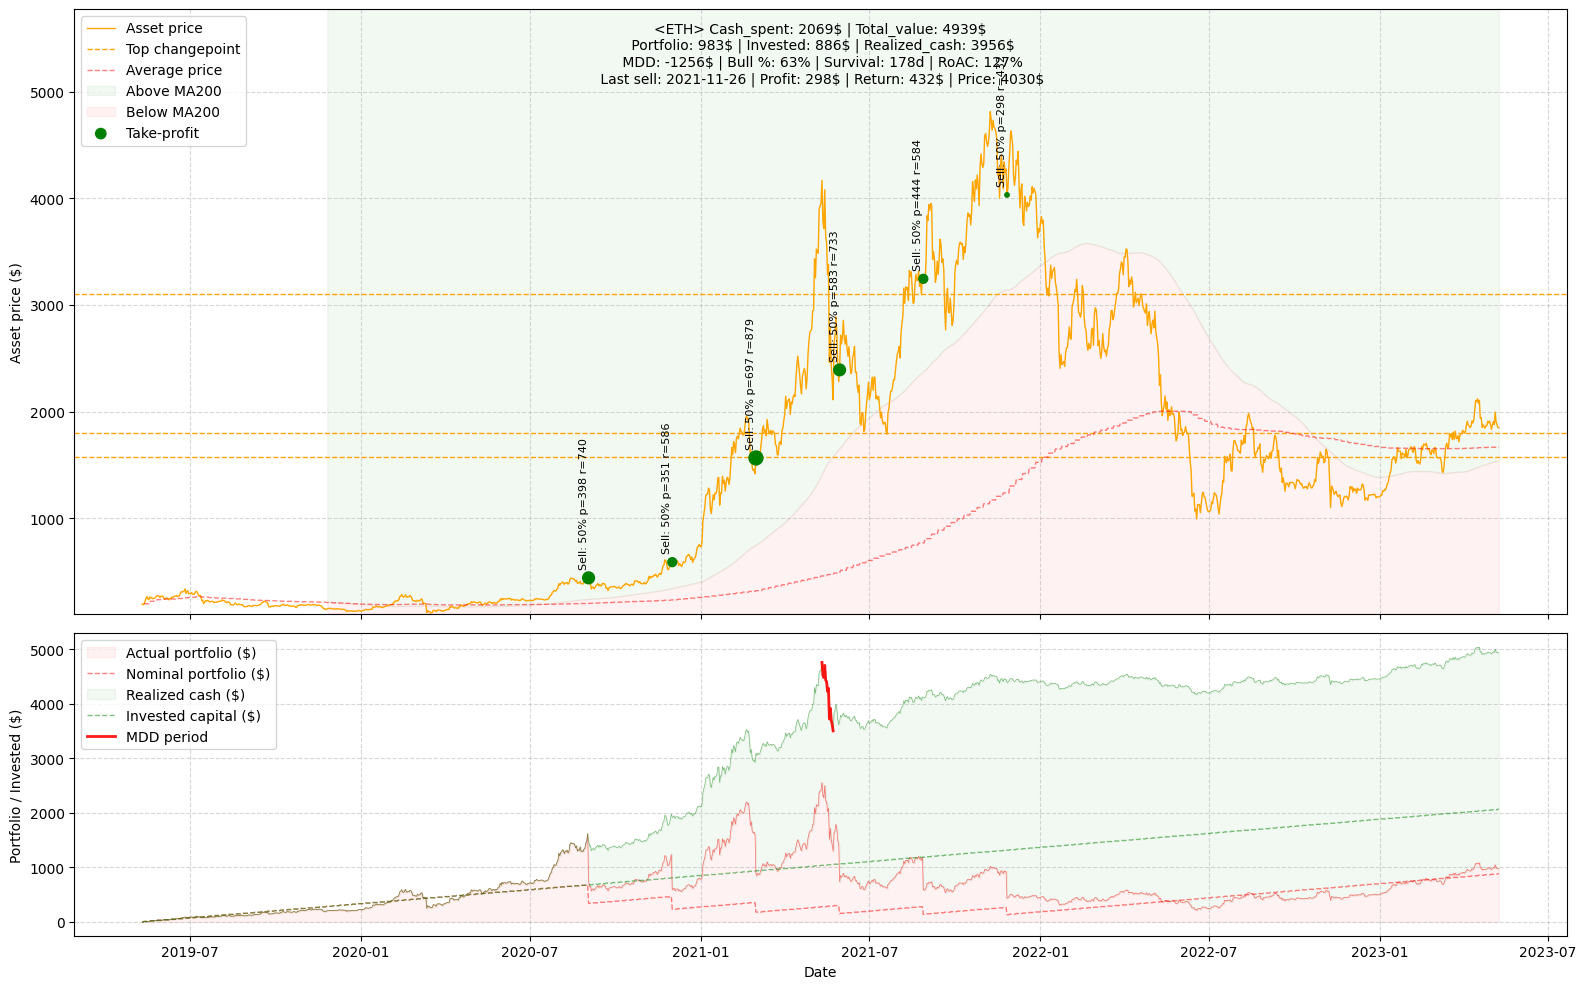

19:04:47 - cmdstanpy - INFO - Chain [1] start processing
19:04:47 - cmdstanpy - INFO - Chain [1] done processing


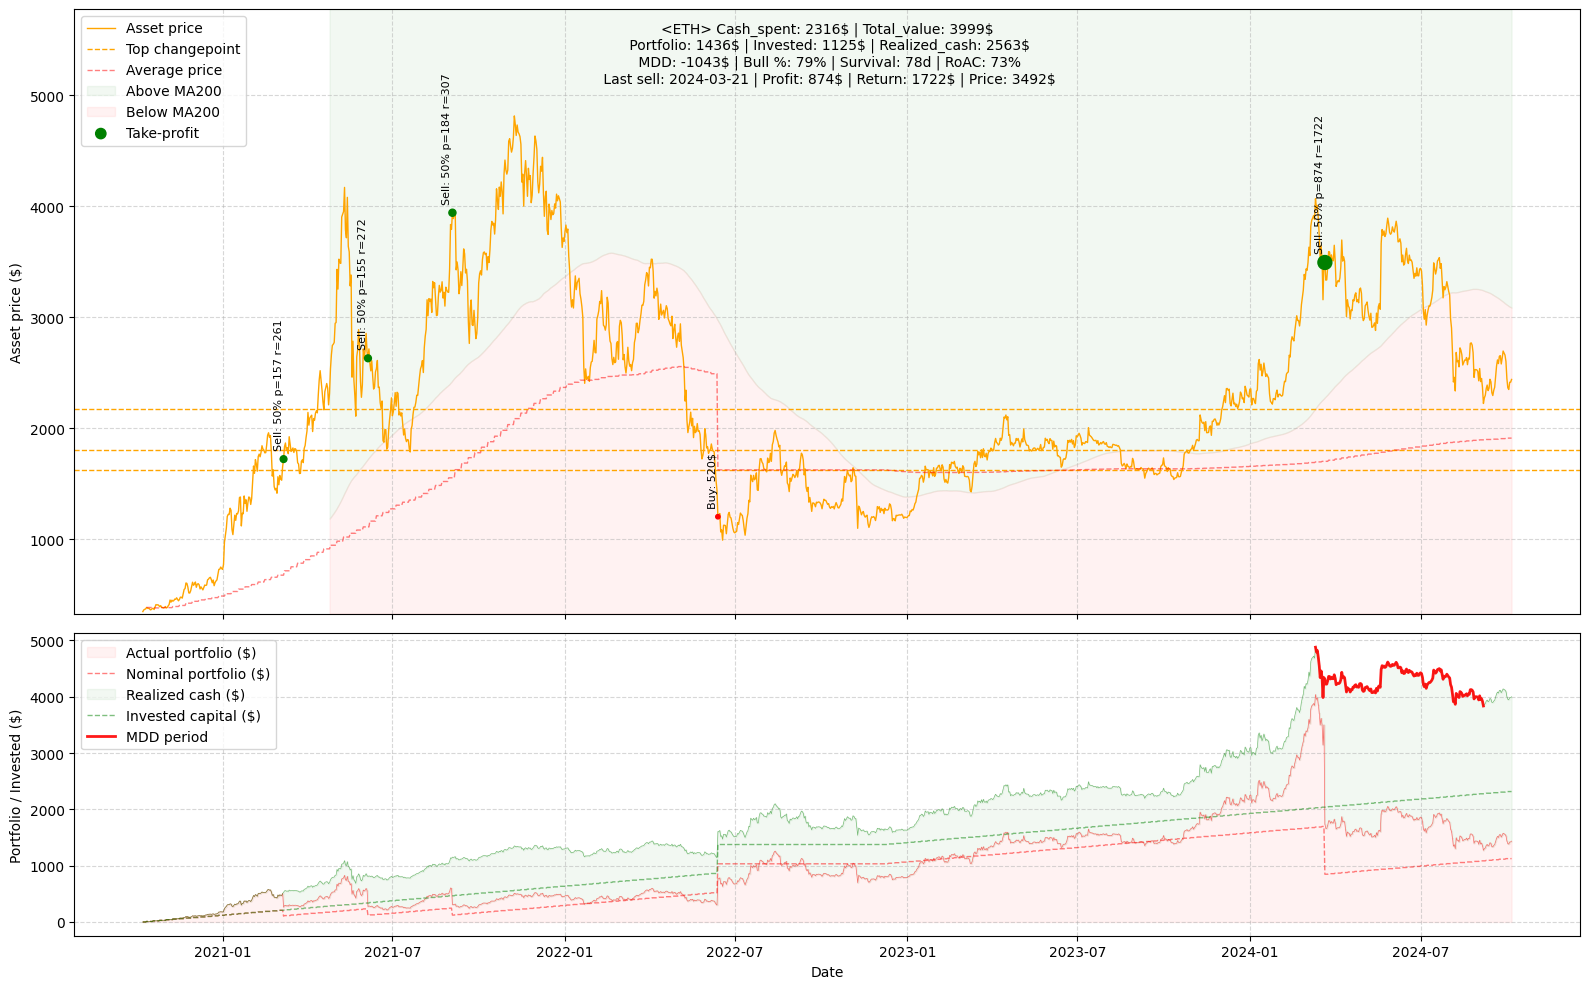

19:04:48 - cmdstanpy - INFO - Chain [1] start processing
19:04:48 - cmdstanpy - INFO - Chain [1] done processing


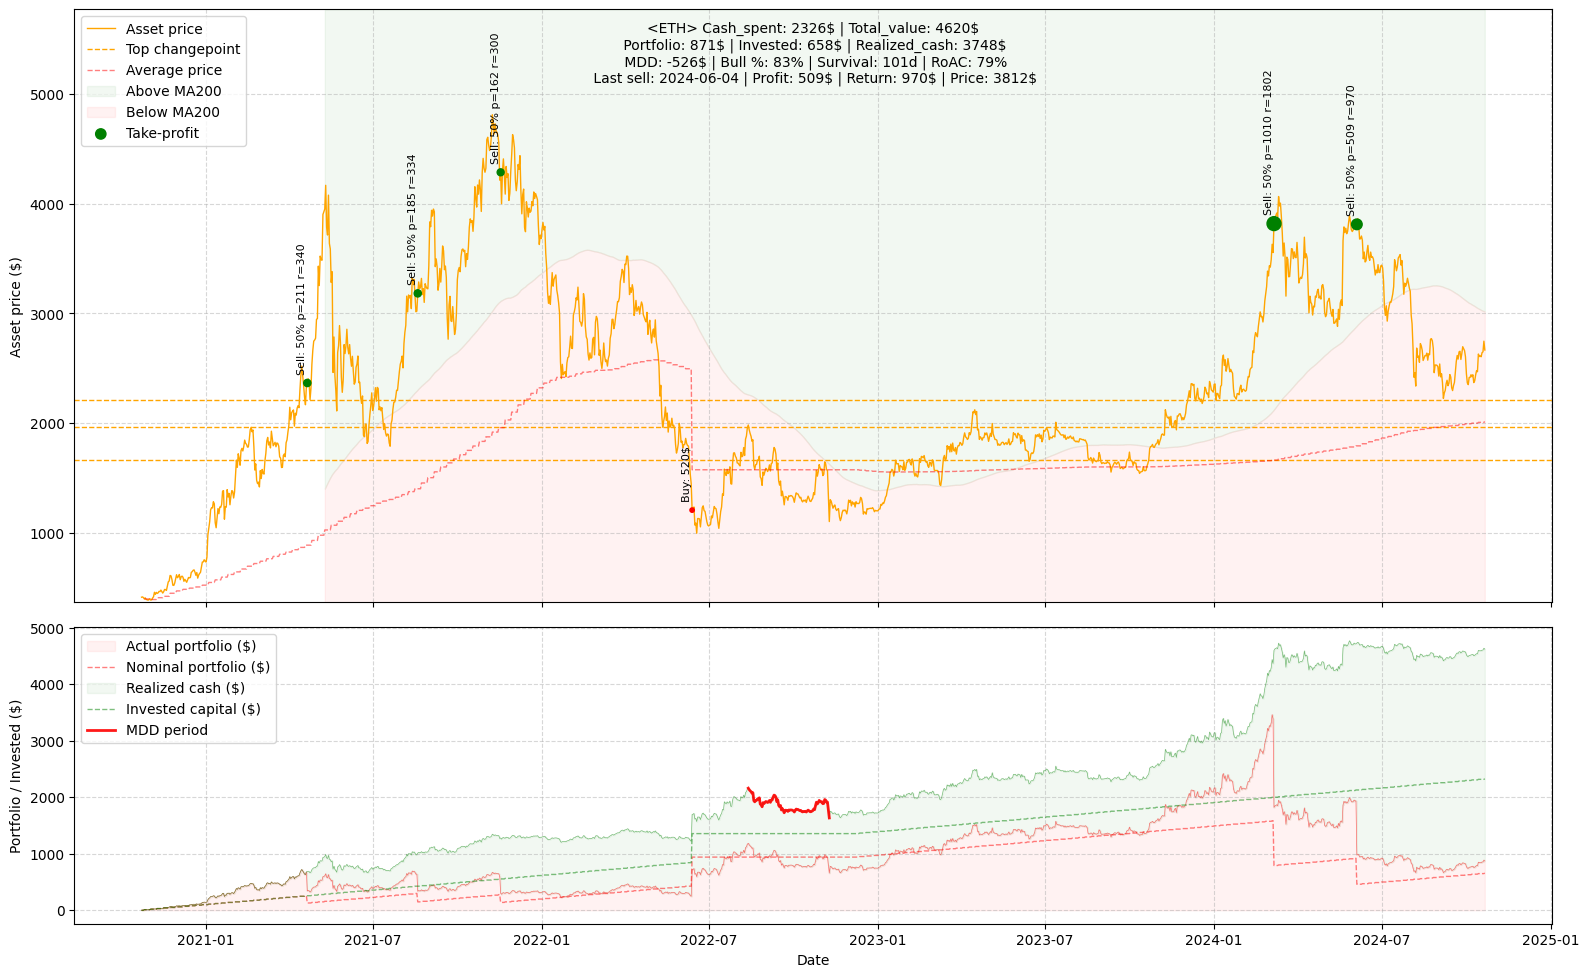

19:04:48 - cmdstanpy - INFO - Chain [1] start processing
19:04:48 - cmdstanpy - INFO - Chain [1] done processing


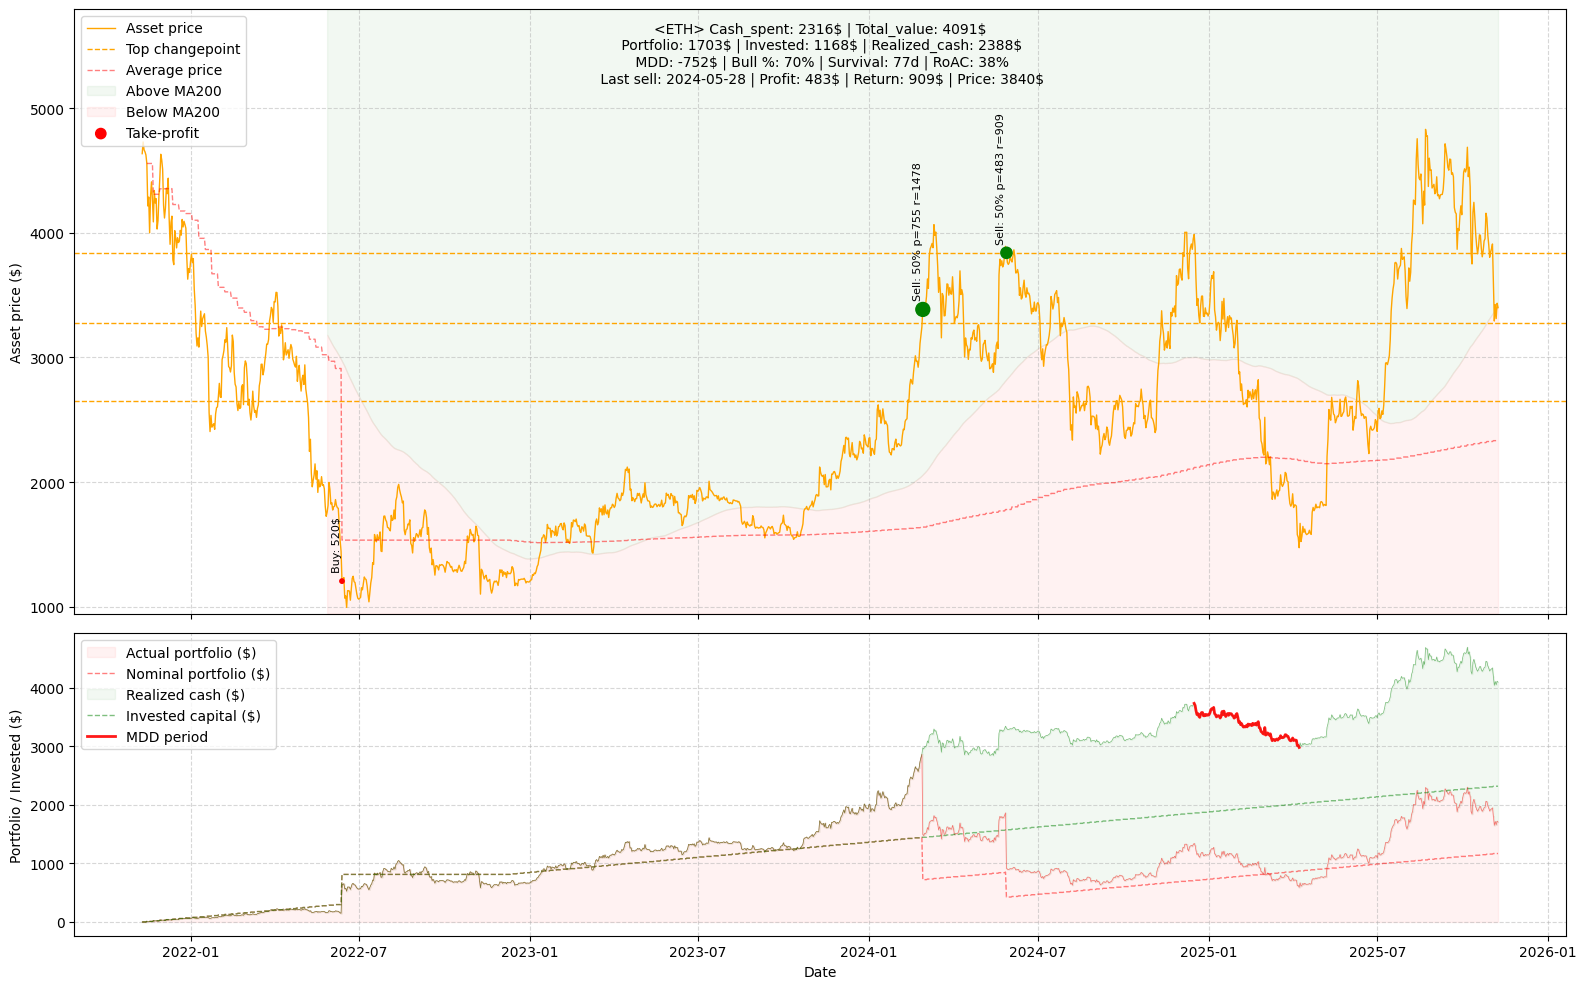

19:04:49 - cmdstanpy - INFO - Chain [1] start processing
19:04:49 - cmdstanpy - INFO - Chain [1] done processing


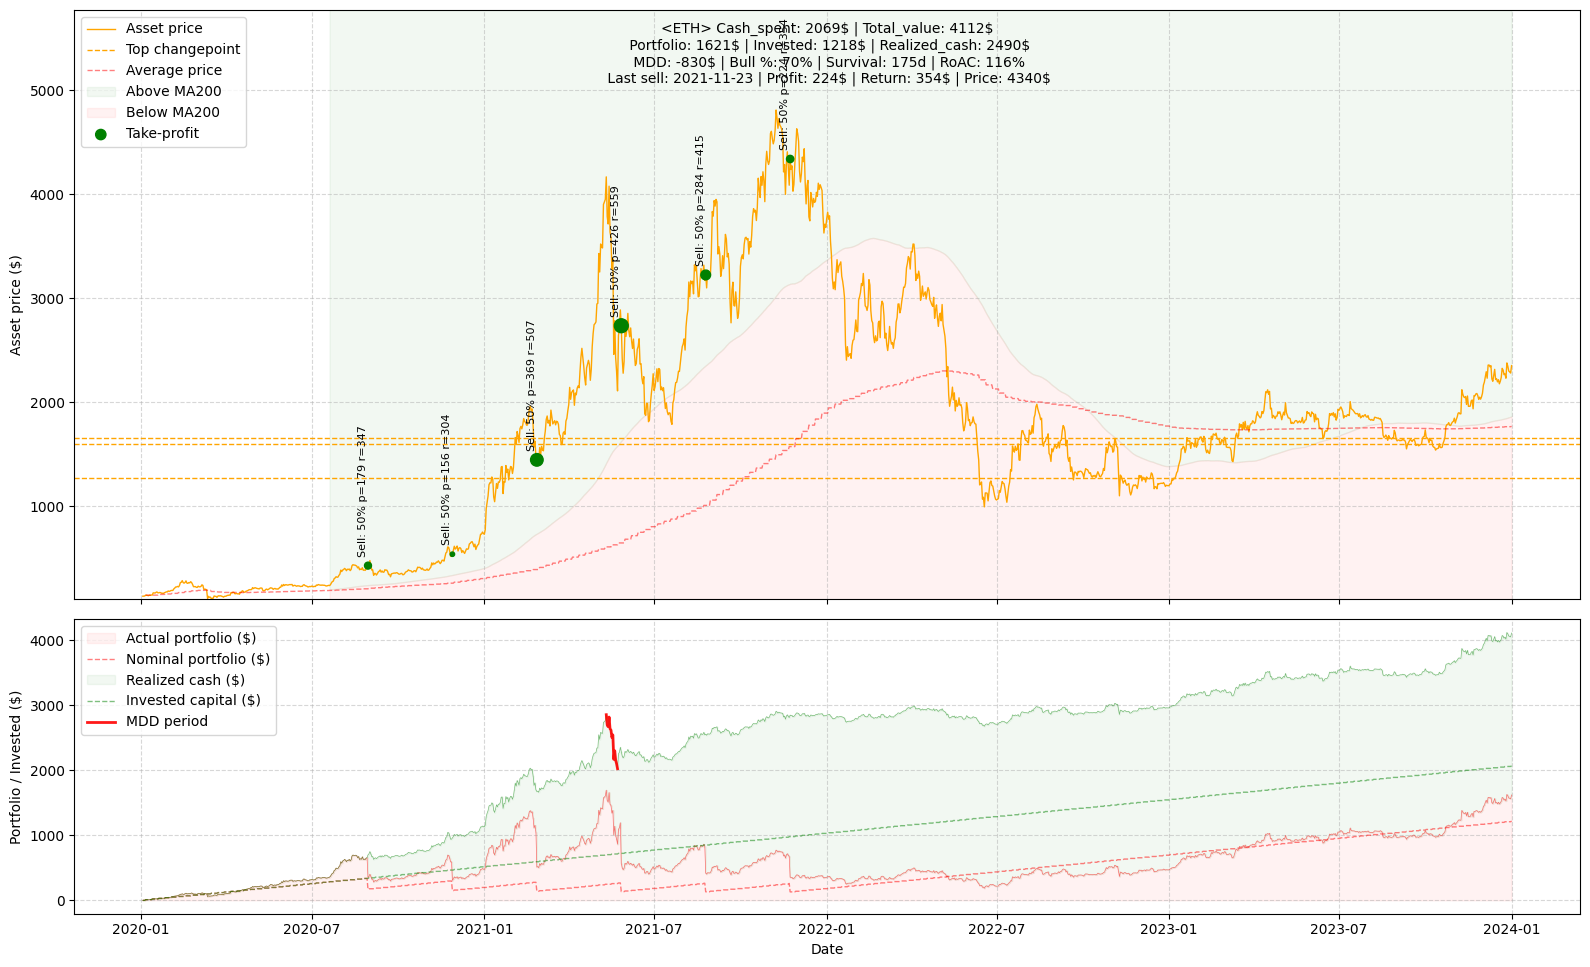

19:04:49 - cmdstanpy - INFO - Chain [1] start processing
19:04:50 - cmdstanpy - INFO - Chain [1] done processing


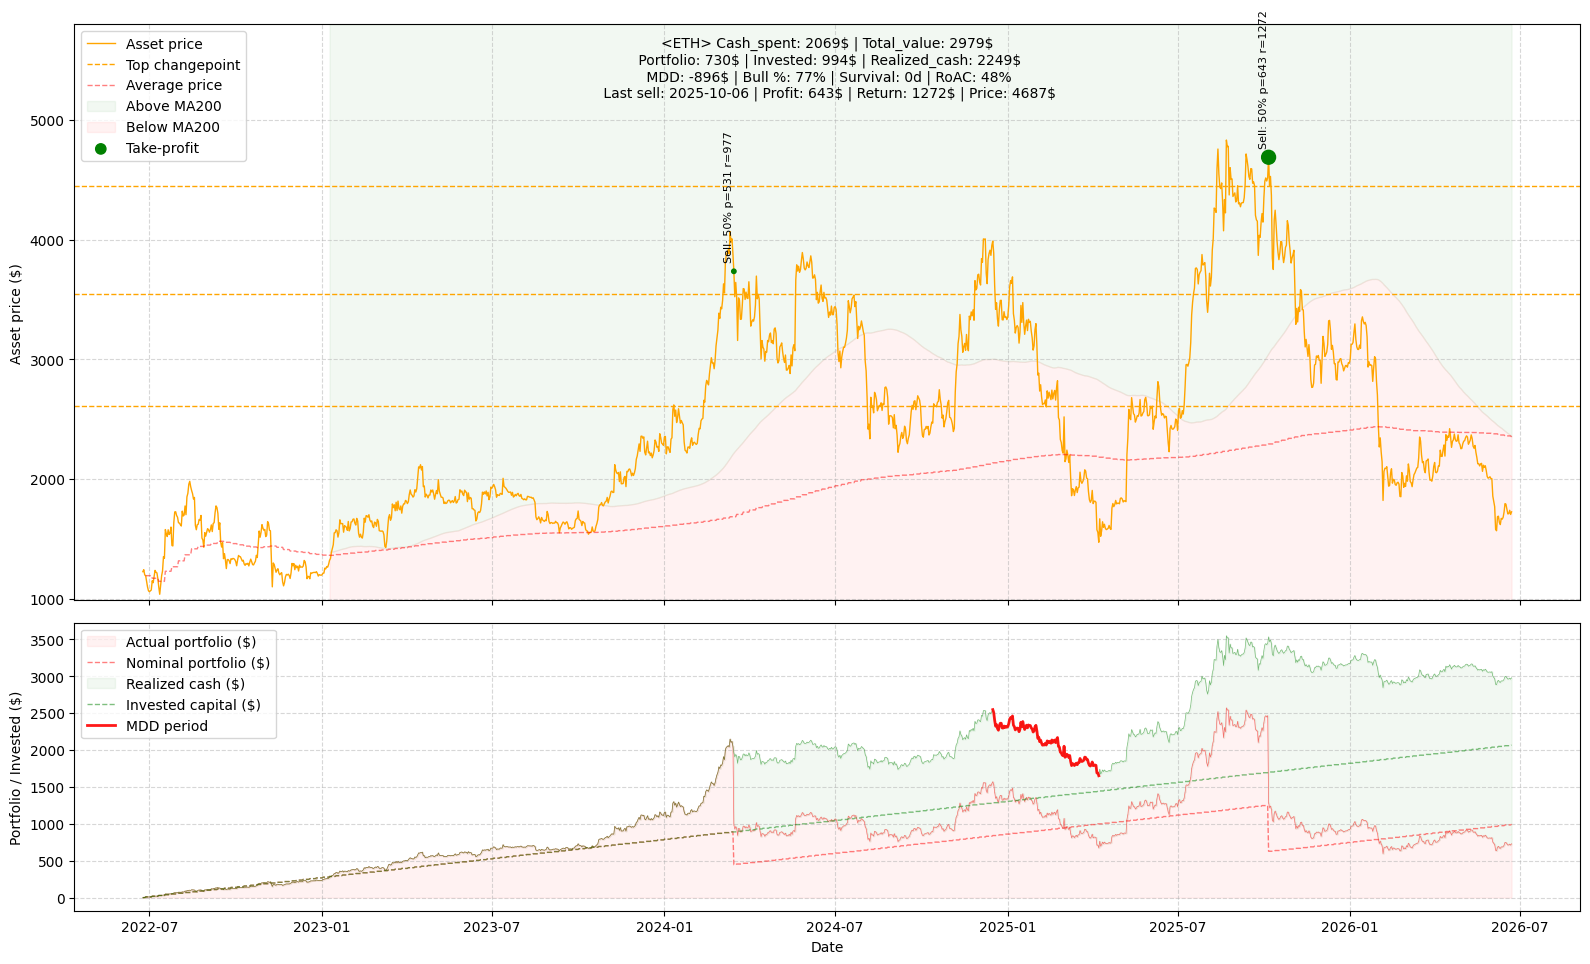

19:04:50 - cmdstanpy - INFO - Chain [1] start processing
19:04:50 - cmdstanpy - INFO - Chain [1] done processing


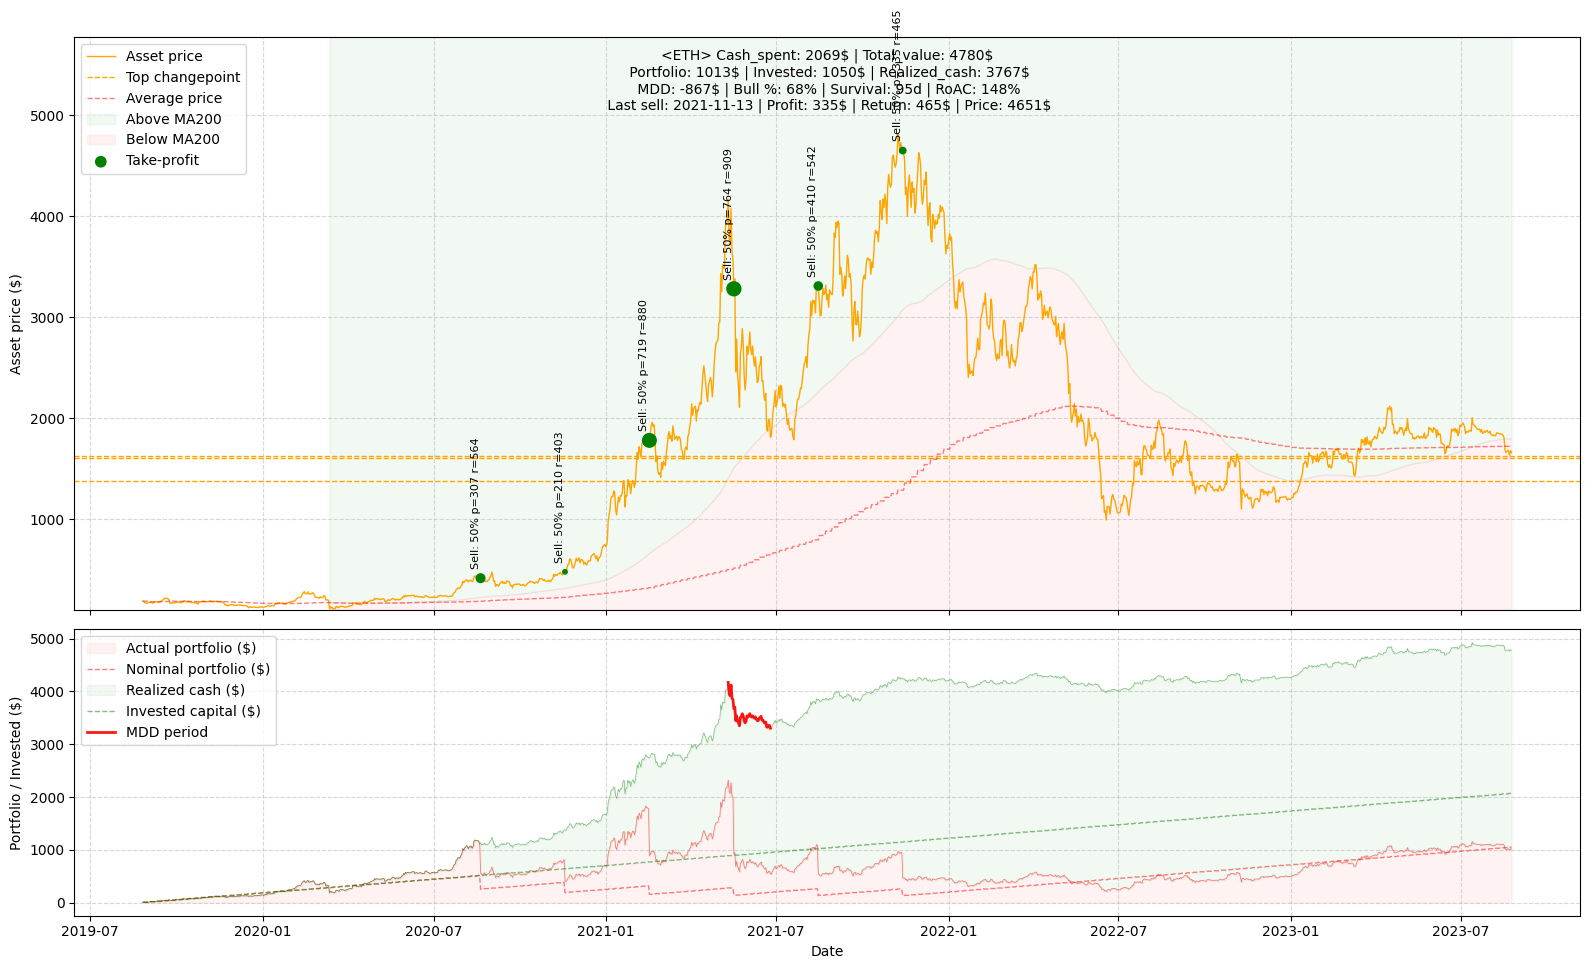

19:04:51 - cmdstanpy - INFO - Chain [1] start processing
19:04:51 - cmdstanpy - INFO - Chain [1] done processing


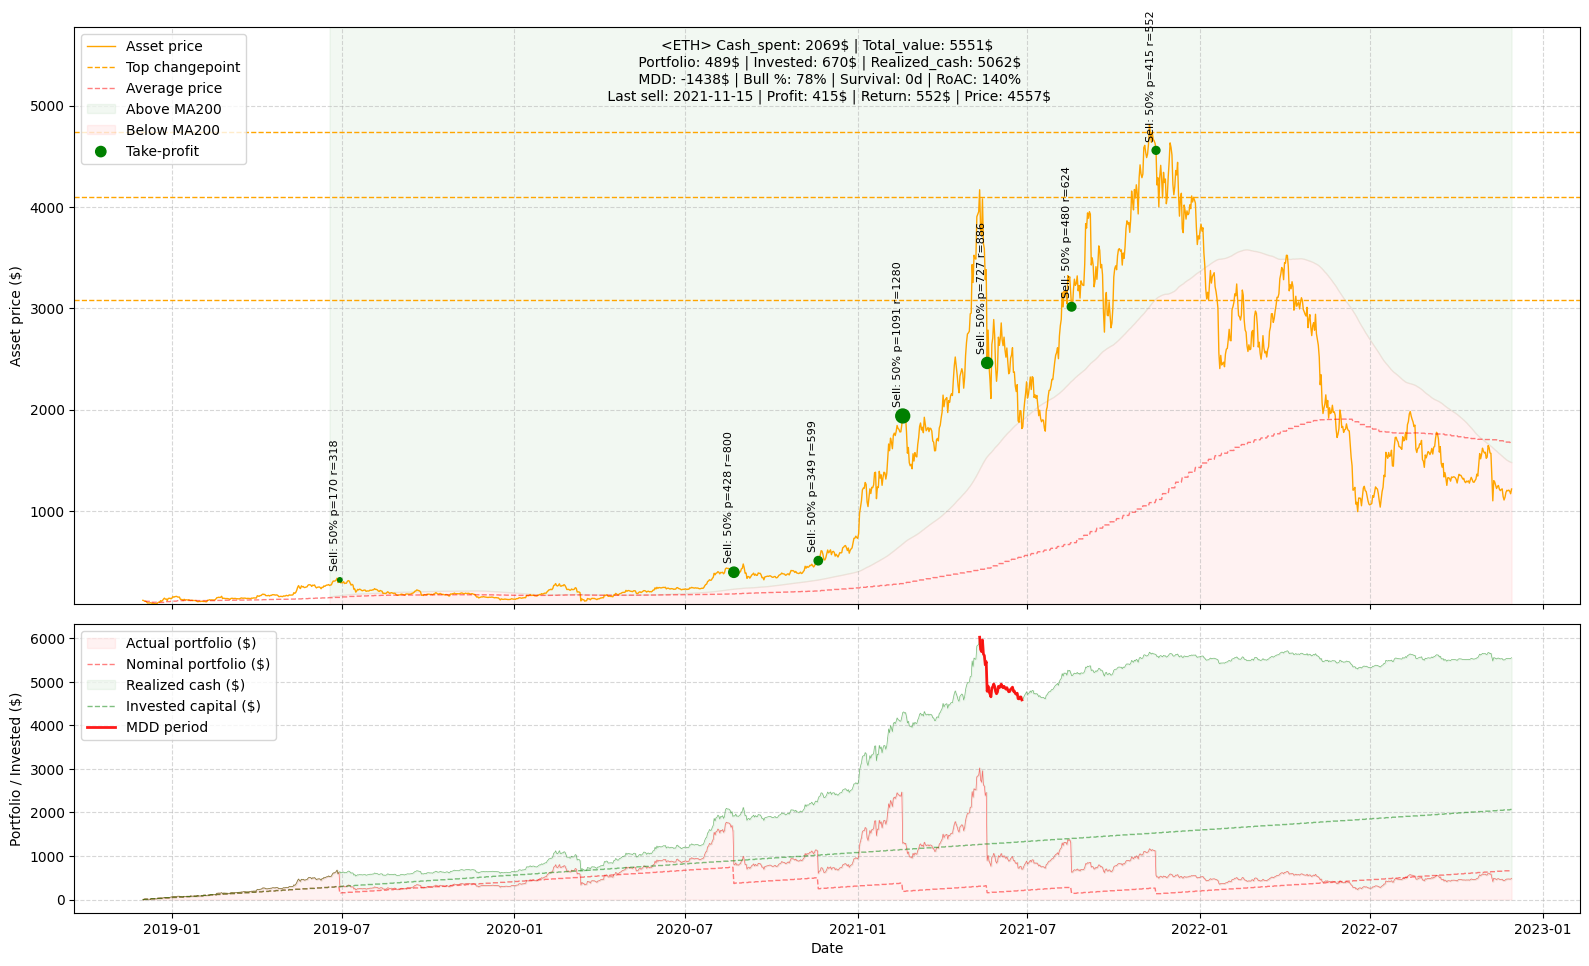

,Target,Cash_spent,Realized_cash,Portfolio,Invested,Total_value,Bull_history,MDD,Survival,RoAC,Period,Start,End
0,ETH,2059,5205,530,672,5736,79,-1677,0.000000,143,1,2018-12-12,2022-12-10
1,ETH,2326,3890,880,523,4771,69,-699,121.000000,41,2,2021-10-25,2025-10-23
2,ETH,2069,3956,983,886,4939,63,-1256,178.500000,127,3,2019-05-11,2023-05-09
3,ETH,2316,2563,1436,1125,3999,79,-1043,77.666667,73,4,2020-10-08,2024-10-06
4,ETH,2326,3748,871,658,4620,83,-526,101.000000,79,5,2020-10-23,2024-10-21
5,ETH,2316,2388,1703,1168,4091,70,-752,77.000000,38,6,2021-11-10,2025-11-08
6,ETH,2069,2490,1621,1218,4112,70,-830,174.666667,116,7,2020-01-03,2024-01-01
7,ETH,2069,2249,730,994,2979,77,-896,0.000000,48,8,2022-06-24,2026-06-22
8,ETH,2069,3767,1013,1050,4780,68,-867,94.750000,148,9,2019-08-26,2023-08-24
9,ETH,2069,5062,489,670,5551,78,-1438,0.000000,140,10,2018-12-01,2022-11-29


In [8]:
all_metrics = []
last_result = None
last_metrics = None

for p in periods:
    period_prices = p["prices"]

    try:
        bt = BacktestDCA(
        target=STOCK,
        prices=period_prices,
        strategy=strategy
        )
        result, metrics = bt.run()
        ploter(metrics=metrics, history=result)
    except Exception as e:
        print(f"Error backtesting {STOCK} on period {p['period_id']}: {e}")
        continue

    metrics = metrics.copy()
    metrics["Period"] = p["period_id"]
    metrics["Start"] = p["start"]
    metrics["End"] = p["end"]
    all_metrics.append(metrics)

    last_result = result
    last_metrics = metrics

summary = pd.DataFrame(all_metrics)
summary

In [9]:
last_result

,Price,Portfolio_qty,Cost_basis,Cash_spent,Profit,Returns,Realized_cash,Trigger_msg,Portfolio,Average_price,Total_value
Date,,,,,,,,,,,
2018-12-01,118.635559,0.000000,0.000000,0.0,0.0,0.0,0.000000,,0.000000,NaN,0.000000
2018-12-02,116.388901,0.000000,0.000000,0.0,0.0,0.0,0.000000,,0.000000,NaN,0.000000
2018-12-03,108.925018,0.090888,9.900000,9.9,0.0,0.0,0.000000,,9.900000,108.925018,9.900000
2018-12-04,110.214188,0.090888,9.900000,9.9,0.0,0.0,0.000000,,10.017170,108.925018,10.017170
2018-12-05,102.475555,0.090888,9.900000,9.9,0.0,0.0,0.000000,,9.313820,108.925018,9.313820
...,...,...,...,...,...,...,...,...,...,...,...
2022-11-25,1198.925903,0.393494,660.979687,2059.2,0.0,0.0,5062.019581,,471.770418,1679.769732,5533.789999
2022-11-26,1205.897949,0.393494,660.979687,2059.2,0.0,0.0,5062.019581,,474.513878,1679.769732,5536.533459
2022-11-27,1195.126953,0.393494,660.979687,2059.2,0.0,0.0,5062.019581,,470.275553,1679.769732,5532.295134


In [10]:
last_metrics

{'Target': 'ETH',
 'Cash_spent': 2069,
 'Realized_cash': 5062,
 'Portfolio': 489,
 'Invested': 670,
 'Total_value': 5551,
 'Bull_history': 78,
 'MDD': -1438,
 'Survival': 0.0,
 'RoAC': 140,
 'Period': 10,
 'Start': Timestamp('2018-12-01 00:00:00'),
 'End': Timestamp('2022-11-29 00:00:00')}